In [47]:
import os
import torch
import torch.distributions as dist
import torch.nn as nn
from typing import List
from tqdm import tqdm

from utils import load_mnist_dataset, flatten_image, unflatten_image, view_image
from unet import get_timestep_embedding, UNet

In [48]:
# Create the "Img" folder if it does not exist
if not os.path.exists('imgs'):
    os.makedirs('imgs')

In [2]:
#load_mnist_dataset()
trainY, testY = load_mnist_dataset()

In [3]:
len(trainY)

60000

In [4]:
trainY[0].shape

torch.Size([784])

In [5]:
28*28

784

In [6]:
def sample_multivariate_gaussian(mean, covariance, num_samples=1):
    """
    Function to sample from an N-dimensional multivariate Gaussian distribution
    :param mean:
    :param covariance:
    :param num_samples:
    :return:
    """
    # Create a multivariate normal distribution
    mvn = dist.MultivariateNormal(mean, covariance)
    # Sample from the distribution
    samples = mvn.sample((num_samples,))
    return samples

def unflatten_data(vector, shape=(28, 28)):
    """
    Function to unflatten an image
    :param vector: Flattened image tensor
    :param shape: Target shape
    :return: Unflattened image tensor
    """
    return vector.view(-1, 1, *shape)

def sample_batch(trainY, batch_size, device):
    indices = torch.randperm(len(trainY))[:batch_size]
    data = torch.stack([trainY[i] for i in indices]).to(device)
    data = unflatten_data(data)  # Reshape to (batch_size, 1, 28, 28)
    return torch.nn.functional.interpolate(data, size=(32, 32))

def save_samples(diffusion_model, nb_images, n_batch):
    samples = diffusion_model.sampling(n_samples=nb_images, use_tqdm=False)
    plt.figure(figsize=(17, 17))
    for i in range(nb_images):
        plt.subplot(9, 9, 1 + i)
        plt.axis('off')
        plt.imshow(samples[i].squeeze(0).clip(0, 1).data.cpu().numpy(), cmap='gray')
    plt.savefig(f'imgs/samples_epoch_{n_batch}.png')
    plt.close()


In [7]:
mean = torch.tensor([0.0, 0.0])  # Example mean for a 2D Gaussian
covariance_matrix = torch.tensor([[1.0, 0.5], [0.5, 1.0]])  # Example covariance matrix


In [8]:
sample_multivariate_gaussian(mean=mean, covariance=covariance_matrix, num_samples=2)

tensor([[-0.6106,  0.2207],
        [ 1.3926,  0.8736]])

In [9]:
t_sample = torch.rand(10,device='cuda', dtype=torch.float32)
t_sample.shape
t_sample = t_sample.unsqueeze(1).unsqueeze(2).unsqueeze(3)  # Shape: (10, 1, 1, 1)

In [10]:
test_sample_y = sample_batch(trainY, batch_size=10, device='cuda')

In [11]:
x_sample = torch.randn(test_sample_y.shape, device='cuda')
x_sample.shape

torch.Size([10, 1, 32, 32])

In [12]:
prod = torch.randn(test_sample_y.shape, device='cuda')*t_sample
prod.shape

torch.Size([10, 1, 32, 32])

In [13]:
test_sample_y.shape

torch.Size([10, 1, 32, 32])

In [14]:
test_sample_y[0][0][23]

tensor([-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -0.9922, -0.3569,  0.7725,  0.9843,  0.9294,
        -0.5294, -0.5294, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000],
       device='cuda:0')

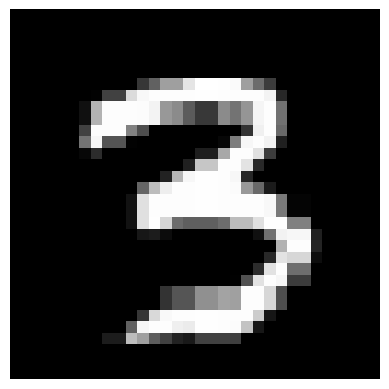

In [15]:
view_image(test_sample_y.cpu()[0])

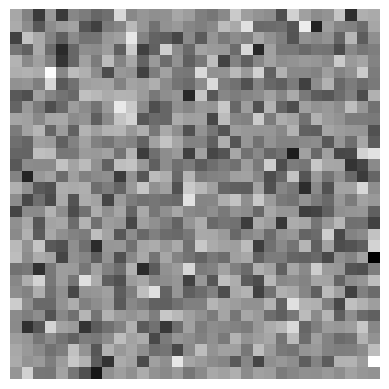

In [16]:
view_image(x_sample.cpu()[0])

In [17]:
get_timestep_embedding(torch.tensor([0.4]), embedding_dim=12)

tensor([[3.8942e-01, 6.3353e-02, 1.0047e-02, 1.5924e-03, 2.5238e-04, 4.0000e-05,
         9.2106e-01, 9.9799e-01, 9.9995e-01, 1.0000e+00, 1.0000e+00, 1.0000e+00]])

In [65]:
class SimpleBrownianBridgeDiffusion:

    def __init__(self, T: float, model: nn.Module, device: str, trainY: List):
        self.T = T
        self.function_approximator = model.to(device)
        self.device = device
        self.trainY = trainY

        self._EPS = 0.0000001


    def train(self, batch_size, optimizer):
        """
        Corollary 2.7 implementation
        """

        # sample target images y
        y = sample_batch(self.trainY, batch_size, self.device)
        # sample random times from [0,T)
        t = torch.rand(batch_size,device=self.device, dtype=torch.float32)*self.T
        # Unsqueeze t to align dimensions
        t = t.unsqueeze(1).unsqueeze(2).unsqueeze(3)  # Shape: (batch_size, 1, 1, 1)
        # sample x as independent gaussians 
        x = torch.randn(y.shape, device=self.device)
        # compute E_t
        E = x + (y-x)*t/self.T
        # compute V_t
        V = t*(self.T-t)/self.T
        # compute xi_t sampling 
        xi = x + torch.randn(y.shape, device=self.device)*torch.sqrt(V)
        # Take one gradient descent step
        # The input to function_approximator must be 4D: (batch_size, channels, height, width)
        # t is a list of times [batch_size] (hence squeeze)
        img_predicted = self.function_approximator(xi, t.squeeze())
        loss = nn.functional.mse_loss(y, img_predicted)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        return loss.item()

    @torch.no_grad()
    def sampling(self, n_samples=1, image_channels=1, img_size=(32, 32), n_steps=100,
                 use_tqdm=True):
        """
        Corollary 2.9 implementation
        """
        # create n_steps t
        t_values = torch.linspace(0, self.T - self._EPS, steps=n_steps)

        # sample x
        delta = (self.T - self._EPS)/ n_steps
        x = torch.randn((n_samples, image_channels, img_size[0], img_size[1]),
                        device=self.device)

        xi_t = x
        Z_t = x
        
        progress_bar = tqdm if use_tqdm else lambda x: x
        for t in progress_bar(t_values):
            t = torch.tensor(t, device=self.device) 
            inv_lambda = 1/(self.T - t)
            # mu_t = x; Sigma_tt = t
            Z = x + torch.randn(x.shape, device=self.device)*torch.sqrt(t)
            # need a list of repeated t with len same as n_samples
            t_list = [t for _ in range(n_samples)]
            xi = xi_t + inv_lambda*(self.function_approximator(xi_t, torch.stack(t_list)) - xi_t )*delta + (Z - Z_t)

            xi_t = xi
            Z_t = Z
        return xi

In [66]:
device = 'cuda'
batch_size = 64 
model = UNet()
optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)

In [67]:
diffusion_model = SimpleBrownianBridgeDiffusion(10, model, device, trainY)

In [73]:
# Training
for n_batch in tqdm(range(40000)):
    loss = diffusion_model.train(batch_size, optimizer)

  9%|▉         | 3558/40000 [09:59<1:42:23,  5.93it/s]


KeyboardInterrupt: 

In [ ]:
# Save sampled images every 2000 epochs
if (n_batch + 1) % 1000 == 0:
    save_samples(diffusion_model, nb_images=81, n_batch=n_batch + 1)

In [74]:
samples = diffusion_model.sampling(n_samples=1, use_tqdm=False)

/tmp/ipykernel_129662/3557570241.py:61: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t, device=self.device)


In [75]:
samples.shape

torch.Size([1, 1, 32, 32])

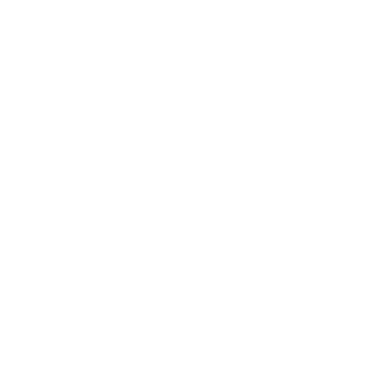

In [76]:
view_image(samples.cpu()[0])